# Clasificación de radiografías de tórax
### Trabajo final de Inteligencia Artificial · Normal, COVID-19 y Viral Pneumonia

**Pregunta.** ¿Qué rendimiento tiene una ResNet-18 al clasificar las etiquetas de esta colección en una partición reservada?

**Resultado de la corrida original.** En 2.274 imágenes de test, la red obtuvo **97,01% de accuracy** y **0,9627 de macro-F1**. La referencia que predice siempre Normal obtuvo **67,24%** y **0,2680**, respectivamente. La red se entrenó desde cero en CPU.

Este cuaderno se abre desde la raíz del proyecto. Las celdas muestran la auditoría guardada, comprueban el cargador con un batch de entrenamiento y recalculan las métricas desde las predicciones originales. La corrida completa se puede regenerar con la celda opcional de entrenamiento. El [README](README.md) explica cómo preparar el entorno.

Abrí la carpeta del repositorio y elegí el kernel del entorno local. La auditoría, las curvas y las métricas se pueden ejecutar con los CSV incluidos. Descargá las radiografías si querés volver a abrir imágenes o entrenar el modelo. El [README](README.md) indica dónde ponerlas.

In [1]:
from pathlib import Path
import hashlib
import io
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as NotebookImage, display
from PIL import Image

raiz = Path.cwd()
datos = raiz / "data/raw/COVID-19_Radiography_Dataset"
auditoria = raiz / "results/audit"
corrida = raiz / "results/baseline"
ruta_manifiesto = raiz / "data/processed/manifest.csv"

assert ruta_manifiesto.is_file(), "Abrí el notebook desde la raíz del proyecto."
hay_imagenes = datos.is_dir()
config = json.loads((corrida / "config.json").read_text())
clases = config["classes"]  # COVID es el nombre de carpeta para COVID-19.
semilla = config["seed"]

def mostrar_figura(figura):
    # Guardar la figura en la salida del notebook para verla sin volver a ejecutar.
    archivo = io.BytesIO()
    figura.savefig(archivo, format="png", dpi=105, bbox_inches="tight")
    display(NotebookImage(data=archivo.getvalue()))
    plt.close(figura)

print(f"Dataset: {datos.relative_to(raiz)} · Semilla: {semilla}")

Dataset: data/raw/COVID-19_Radiography_Dataset · Semilla: 20261115


## 1. Revisar las imágenes y su procedencia

Las entradas salen de `images/`. Las máscaras son anotaciones auxiliares. `Lung_Opacity` queda disponible para otro experimento. El auditor original recorrió las cuatro carpetas, abrió cada PNG, midió dimensiones e intensidades y unió los Excel con el nombre de archivo, ignorando mayúsculas y minúsculas. El detalle está en [audit.py](src/audit.py). El comando `bash run_python.sh src/audit.py` vuelve a leer los PNG y regenera el manifiesto y la partición con la misma semilla.

In [2]:
manifiesto = pd.read_csv(ruta_manifiesto, keep_default_na=False)
resumen = json.loads((auditoria / "summary.json").read_text())
publicados = pd.Series({"Normal": 10192, "COVID": 3616, "Viral Pneumonia": 1345, "Lung_Opacity": 6012})

if hay_imagenes:
    # Contamos los archivos actuales y contrastamos el resultado con la auditoría.
    presentes = pd.Series({
        etiqueta: sum(archivo.is_file() for archivo in (datos / etiqueta / "images").iterdir())
        for etiqueta in publicados.index
    })
else:
    # Usar el inventario guardado si el dataset no está descargado.
    presentes = manifiesto.label.value_counts().reindex(publicados.index)
    print("Conteos del manifiesto de la auditoría original.")
conteo = pd.DataFrame({"Publicadas": publicados, "Presentes": presentes})
conteo["Diferencia"] = conteo["Presentes"] - conteo["Publicadas"]
display(conteo)

assert manifiesto["error"].eq("").all()
print("Rango global de intensidad:", manifiesto.intensity_min.min(), "a", manifiesto.intensity_max.max())
display(manifiesto.groupby(["label", "width", "height", "channels"]).size().rename("Archivos").to_frame())

,Publicadas,Presentes,Diferencia
Normal,10192,10192,0
COVID,3616,3616,0
Viral Pneumonia,1345,1345,0
Lung_Opacity,6012,6012,0


Rango global de intensidad: 0 a 255


Archivos
label           width height channels          
COVID           299   299    1             3616
Lung_Opacity    299   299    1             6012
Normal          299   299    1            10192
Viral Pneumonia 299   299    1             1205
                             3              140

Los archivos miden **299 × 299**. El campo de tamaño en los Excel dice 256 × 256, así que para el análisis vale la dimensión medida al abrir el archivo. Las 140 imágenes RGB de Viral Pneumonia tienen los tres canales idénticos.

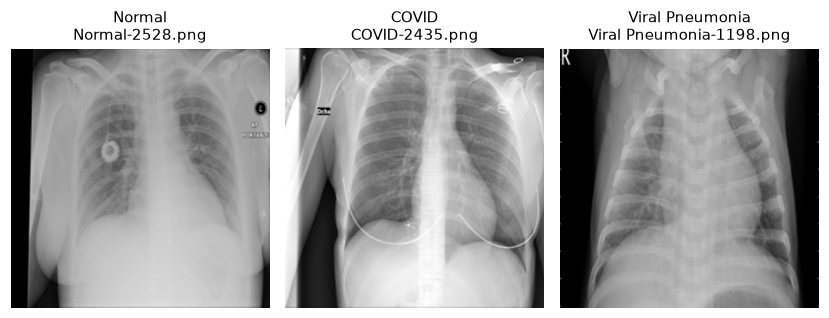

In [3]:
if hay_imagenes:
    figura, ejes = plt.subplots(1, 3, figsize=(8, 3))
    for eje, etiqueta in zip(ejes, clases):
        fila = manifiesto[manifiesto.label == etiqueta].sample(1, random_state=semilla).iloc[0]
        with Image.open(raiz / fila.path) as imagen:
            eje.imshow(imagen.convert("L"), cmap="gray", vmin=0, vmax=255)
        eje.set_title(f"{etiqueta}\n{fila.filename}", fontsize=10)
        eje.axis("off")
    figura.tight_layout()
    mostrar_figura(figura)
else:
    print("Descargá las imágenes según el README para ejecutar esta celda.")

In [4]:
# Cada URL identifica la colección de procedencia disponible en los Excel.
display(pd.crosstab(manifiesto.source, manifiesto.label))
print("Archivos con ID de paciente en el manifiesto:", manifiesto.patient_id.ne("").sum())

label,COVID,Lung_Opacity,Normal,Viral Pneumonia
source,,,,
https://bimcv.cipf.es/bimcv-projects/bimcv-covid19/#1590858128006-9e640421-6711,2474,0,0,0
https://eurorad.org,258,0,0,0
https://github.com/armiro/COVID-CXNet,400,0,0,0
https://github.com/ieee8023/covid-chestxray-dataset,182,0,0,0
https://github.com/ml-workgroup/covid-19-image-repository/tree/master/png,183,0,0,0
https://sirm.org/category/senza-categoria/covid-19/,119,0,0,0
https://www.kaggle.com/c/rsna-pneumonia-detection-challenge/data,0,6012,8851,0
https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia,0,0,1341,1345


Archivos con ID de paciente en el manifiesto: 0


Los Excel traen nombre de archivo, formato, tamaño declarado y URL. Los números de archivo no permiten identificar pacientes. Las fuentes de COVID son exclusivas de esa etiqueta. Viral Pneumonia proviene de una colección que también aporta 1.341 Normal. El modelo podría aprovechar diferencias de adquisición, encuadre o marcas en la imagen. Por eso el resultado mide rendimiento dentro de esta colección.

## 2. Agrupar imágenes repetidas antes de partir

- **SHA-256 de archivo** detecta copias con los mismos bytes. El hash de píxeles también encuentra archivos con codificación distinta que se ven idénticos.
- **pHash** resume visualmente la imagen. El auditor busca pares cuya huella difiere en hasta cuatro bits. Después usa **SSIM** y diferencia de intensidad para filtrar esas coincidencias. Agrupa por precaución los pares con SSIM ≥ 0,90 que pasaron la búsqueda de pHash, incluidos los de mayor similitud.
- Las relaciones se unen por transitividad. Si A se agrupa con B y B con C, los tres quedan juntos. Un grupo con etiquetas contradictorias se excluiría entero. En esta corrida no apareció ninguno con los criterios usados.

In [5]:
print("Copias redundantes por bytes:", resumen["exact_byte_duplicate_excess"])
print("Copias redundantes por píxeles:", resumen["exact_pixel_duplicate_excess"])
print("Pares visuales candidatos:", resumen["visual_candidates"])
print("Pares que pasan el criterio visual estricto:", resumen["confirmed_visual"])
print("Grupos con etiquetas contradictorias:", resumen["conflicting_groups"])

usadas = manifiesto[manifiesto.split.isin(["train", "val", "test"])].copy()
for identificador in ["duplicate_group", "pixel_sha256"]:
    # Cada grupo y cada contenido exacto deben aparecer en una sola partición.
    assert usadas.groupby(identificador).split.nunique().max() == 1

particion = pd.crosstab(usadas.label, usadas.split).loc[clases, ["train", "val", "test"]]
display(particion.rename(columns={"train":"Entrenamiento", "val":"Validación", "test":"Test"}))
assert hashlib.sha256(ruta_manifiesto.read_bytes()).hexdigest() == config["manifest_sha256"]
assert hashlib.sha256((raiz / "data/processed/splits.csv").read_bytes()).hexdigest() == config["split_sha256"]

Copias redundantes por bytes: 54
Copias redundantes por píxeles: 59
Pares visuales candidatos: 1720
Pares que pasan el criterio visual estricto: 234
Grupos con etiquetas contradictorias: 0


split,Entrenamiento,Validación,Test
label,,,
Normal,7134,1529,1529
COVID,2530,543,543
Viral Pneumonia,941,202,202


La separación apunta a **70/15/15 por clase**. Con la semilla fija, el auditor mezcla grupos, procesa primero los más grandes y asigna cada grupo entero según cuánto le falta a cada partición para alcanzar su proporción. Las copias se conservan y cuentan como archivos. Este control reduce la fuga por repeticiones detectadas. Queda abierta la posibilidad de estudios distintos de una misma persona o copias muy transformadas.

## 3. Preparar un batch y comprobar la red

La imagen se pasa a gris, se replica en tres canales y se lleva a **224 × 224**. Se usan las constantes de normalización de ImageNet, sin estimar estadísticas con validación o test. Solo en entrenamiento se aplican rotaciones de hasta 7°, traslaciones de hasta 3% y una escala entre 0,95 y 1,05. El cargador original está en [train.py](src/train.py).

Cada salida de la red es un **logit**, un puntaje para una clase. La entropía cruzada penaliza los puntajes que asignan poca probabilidad a la etiqueta verdadera. Para que las clases minoritarias tengan más peso, se usa `cantidad total de entrenamiento / (3 × cantidad de la clase)`.

In [6]:
if hay_imagenes:
    import sys
    from importlib.util import module_from_spec, spec_from_file_location

    if not all(nombre in globals() for nombre in ("raiz", "usadas", "particion", "config")):
        raise RuntimeError("Ejecutá el notebook desde el principio hasta llegar a esta celda.")

    try:
        import torch
        from torch import nn
        from torch.utils.data import DataLoader
        from torchvision import models
    except (ImportError, OSError, RuntimeError) as error:
        raise RuntimeError(
            f"No se pudo cargar PyTorch/torchvision con {sys.executable}. "
            "Elegí el kernel Python (proyecto-radiografias) y volvé a ejecutar desde arriba. "
            f"Error original: {error}"
        ) from error

    # Reusar la clase de datos exacta de la ejecución original.
    spec = spec_from_file_location("entrenamiento_rx", raiz / "src/train.py")
    entrenamiento_rx = module_from_spec(spec)
    spec.loader.exec_module(entrenamiento_rx)

    entrenamiento = usadas[usadas.split == "train"]
    pesos = len(entrenamiento) / (len(clases) * particion["train"])
    assert np.allclose(pesos.to_numpy(), config["class_weights"])
    display(pesos.rename("Peso en la pérdida").to_frame())

    # Prueba breve sobre una red nueva y un batch de entrenamiento.
    torch.set_num_threads(config["cpu_threads"])
    torch.manual_seed(semilla)
    modelo_demo = models.resnet18(weights=None)
    modelo_demo.fc = nn.Linear(modelo_demo.fc.in_features, len(clases))
    cargador_demo = DataLoader(
        entrenamiento_rx.Radiographs(entrenamiento, config, train=True),
        batch_size=config["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(semilla),
        num_workers=0,
    )
    imagenes, etiquetas = next(iter(cargador_demo))
    # Un paso de entrenamiento de ejemplo, con un modelo que vive solo en esta celda.
    optimizador_demo = torch.optim.AdamW(modelo_demo.parameters(), lr=config["finetune_lr"])
    optimizador_demo.zero_grad(set_to_none=True)
    logits = modelo_demo(imagenes)
    perdida = nn.CrossEntropyLoss(weight=torch.tensor(pesos.to_numpy(), dtype=torch.float32))
    valor_perdida = perdida(logits, etiquetas)
    valor_perdida.backward()

    gradiente = modelo_demo.conv1.weight.grad.norm().item()
    assert imagenes.shape[1:] == (3, 224, 224)
    assert logits.shape == (len(etiquetas), len(clases))
    assert etiquetas.min() >= 0 and etiquetas.max() < len(clases)
    assert torch.isfinite(valor_perdida) and np.isfinite(gradiente) and gradiente > 0
    # AdamW usa los gradientes para actualizar los parámetros.
    optimizador_demo.step()
    print(f"Entrada: {list(imagenes.shape)} · Salida: {list(logits.shape)}")
    print(f"Pérdida: {valor_perdida.item():.3f} · Norma del gradiente: {gradiente:.3f}")
else:
    print("Descargá las imágenes según el README para ejecutar esta celda.")

,Peso en la pérdida
label,
Normal,0.495514
COVID,1.397233
Viral Pneumonia,3.756642


Entrada: [32, 3, 224, 224] · Salida: [32, 3]
Pérdida: 1.405 · Norma del gradiente: 7.159


## 4. Entrenar y elegir el checkpoint

ResNet-18 usa conexiones residuales que permiten que una capa aprenda una corrección sobre su entrada. La última capa se reemplazó por una de **tres salidas**.

1. **Cabeza, una época.** Se congelan el extractor y sus estadísticas de BatchNorm. Solo aprende la última capa, con tasa 0,01. Como el extractor empieza con pesos aleatorios, esta etapa sirve como comprobación del esquema y no aporta transferencia.
2. **Red completa, hasta 20 épocas.** Se habilitan los gradientes en todas las capas y se usa AdamW con tasa inicial 0,001. Cada batch sigue el ciclo predicción → pérdida → gradientes → actualización. En validación se calcula el puntaje sin actualizar pesos.
3. **Selección.** Se guarda el estado con mejor macro-F1 de validación. La tasa baja si la validación se estanca. Early stopping estaba configurado con paciencia de cinco épocas. La corrida llegó al límite de 21 épocas en total.

Los pesos ImageNet no estaban disponibles por un fallo de DNS. Se usó inicialización aleatoria en **CPU Ryzen 9 9950X**, batch 32 y cero workers. La ejecución final tomó aproximadamente **30 minutos efectivos**. El script usa tramos cortos y guarda modelo, optimizador y semillas para reanudar.

In [7]:
# Activar solo para repetir el entrenamiento completo con las imágenes descargadas.
REPETIR_ENTRENAMIENTO = False
if REPETIR_ENTRENAMIENTO:
    import subprocess
    import sys

    assert hay_imagenes, "Primero descargá las imágenes según el README."
    salida = "results/reproduccion_notebook"
    # Cada llamada entrena hasta dos épocas y guarda el estado para continuar.
    while not (raiz / salida / "test_metrics.json").exists():
        subprocess.run([sys.executable, "src/train.py", "--out", salida], cwd=raiz, check=True)
    print(f"Reproducción guardada en {salida}.")
else:
    print("Las siguientes celdas analizan la corrida guardada en results/baseline.")

Las siguientes celdas analizan la corrida guardada en results/baseline.


Época elegida: 18 de 21
Macro-F1 de validación: 0.9668


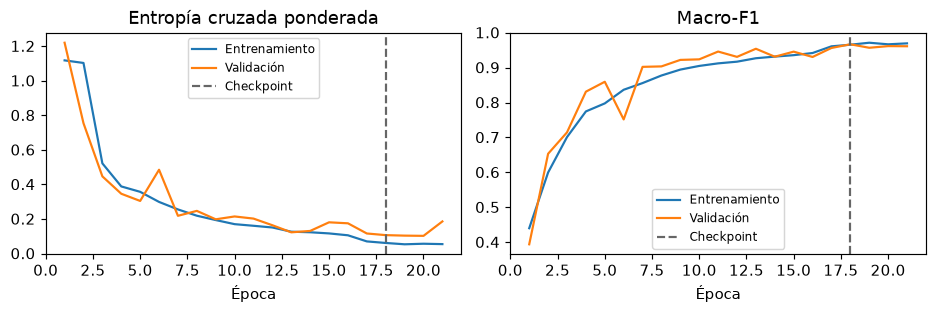

In [8]:
historial = pd.read_csv(corrida / "history.csv")
seleccion = json.loads((corrida / "selection.json").read_text())
epoca_elegida = seleccion["best_epoch"]
assert historial.loc[historial.val_macro_f1.idxmax(), "epoch"] == epoca_elegida
print(f"Época elegida: {epoca_elegida} de {len(historial)}")
print(f"Macro-F1 de validación: {seleccion['val_macro_f1']:.4f}")

figura, ejes = plt.subplots(1, 2, figsize=(9, 3.1))
for eje, columna, titulo in zip(ejes, ["loss", "macro_f1"], ["Entropía cruzada ponderada", "Macro-F1"]):
    eje.plot(historial.epoch, historial[f"train_{columna}"], label="Entrenamiento")
    eje.plot(historial.epoch, historial[f"val_{columna}"], label="Validación")
    eje.axvline(epoca_elegida, color="0.4", linestyle="--", label="Checkpoint")
    eje.set(xlabel="Época", title=titulo)
    eje.legend(fontsize=8)
figura.tight_layout()
mostrar_figura(figura)

La época 18 tuvo el mejor macro-F1 de validación. Después, la pérdida de entrenamiento siguió bajando y la de validación subió al final. Es compatible con sobreajuste o inestabilidad. La elección del checkpoint se hizo antes de evaluar test.

## 5. Recalcular el resultado en test

**Accuracy** es la proporción total de aciertos. **Balanced accuracy** promedia la sensibilidad de las tres clases. **Macro-F1** promedia el F1 de cada clase, y F1 combina precisión y sensibilidad. La precisión responde cuántas predicciones de una clase fueron correctas. La sensibilidad responde cuántos casos reales de esa clase se recuperaron.

La referencia predice siempre la clase más numerosa de **entrenamiento**. Se comparan ambos modelos en las mismas imágenes de test.

In [9]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

predicciones = pd.read_csv(corrida / "test_predictions.csv")
test = usadas[usadas.split == "test"].set_index("path")
assert predicciones.path.is_unique and set(predicciones.path) == set(test.index)

real = test.loc[predicciones.path, "label"].to_numpy()
probabilidades = predicciones[[f"p_{clase}" for clase in clases]].to_numpy()
assert np.allclose(probabilidades.sum(axis=1), 1, atol=1e-6)
predicho = np.asarray(clases)[probabilidades.argmax(axis=1)]
assert np.array_equal(predicho, predicciones.predicted_label)

mayoritaria = particion["train"].idxmax()
comparacion = {}
for nombre, salida in [
    ("ResNet-18", predicho),
    (f"Siempre {mayoritaria}", np.repeat(mayoritaria, len(real))),
]:
    comparacion[nombre] = {
        "Accuracy": accuracy_score(real, salida),
        "Balanced accuracy": balanced_accuracy_score(real, salida),
        "Macro-F1": f1_score(real, salida, labels=clases, average="macro", zero_division=0),
    }

metricas = pd.DataFrame(comparacion).T
guardadas = json.loads((corrida / "test_metrics.json").read_text())
assert np.allclose(metricas.loc["ResNet-18"], [guardadas[k] for k in ("accuracy", "balanced_accuracy", "macro_f1")])
display(metricas.round(4))

por_clase = pd.DataFrame(classification_report(
    real, predicho, labels=clases, output_dict=True, zero_division=0
)).T.loc[clases]
por_clase = por_clase.rename(columns={"precision":"Precisión","recall":"Sensibilidad","f1-score":"F1","support":"N"})
por_clase["N"] = por_clase["N"].astype(int)
display(por_clase.round(4))

,Accuracy,Balanced accuracy,Macro-F1
ResNet-18,0.9701,0.9617,0.9627
Siempre Normal,0.6724,0.3333,0.2680


,Precisión,Sensibilidad,F1,N
Normal,0.9790,0.9771,0.9781,1529
COVID,0.9472,0.9576,0.9524,543
Viral Pneumonia,0.9648,0.9505,0.9576,202


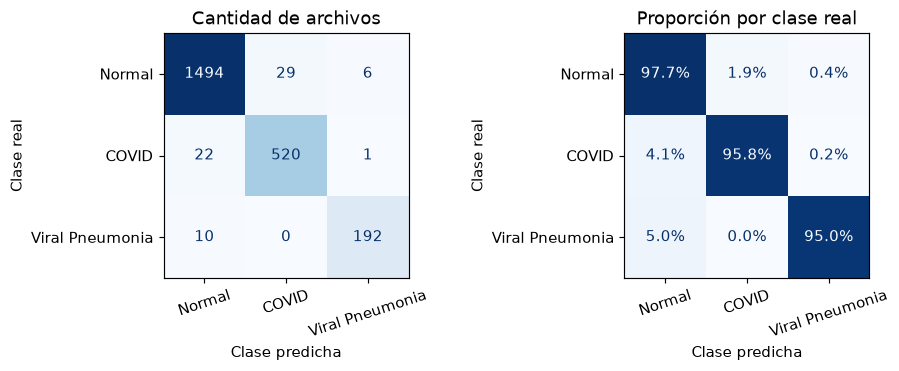

In [10]:
# Las filas son las clases reales y las columnas son las predichas.
figura, ejes = plt.subplots(1, 2, figsize=(9, 3.65))
for eje, normalizar, titulo in zip(ejes, [None, "true"], ["Cantidad de archivos", "Proporción por clase real"]):
    ConfusionMatrixDisplay.from_predictions(
        real, predicho, labels=clases, xticks_rotation=18, normalize=normalizar,
        values_format="d" if normalizar is None else ".1%", ax=eje, cmap="Blues", colorbar=False,
    )
    eje.set(title=titulo, xlabel="Clase predicha", ylabel="Clase real")
figura.tight_layout()
mostrar_figura(figura)

La confusión más común fue entre Normal y COVID-19: **29 Normal → COVID** y **22 COVID → Normal**. En Viral Pneumonia, los **10 errores** fueron predicciones Normal. La matriz normalizada muestra qué proporción representan esos errores dentro de cada clase real.

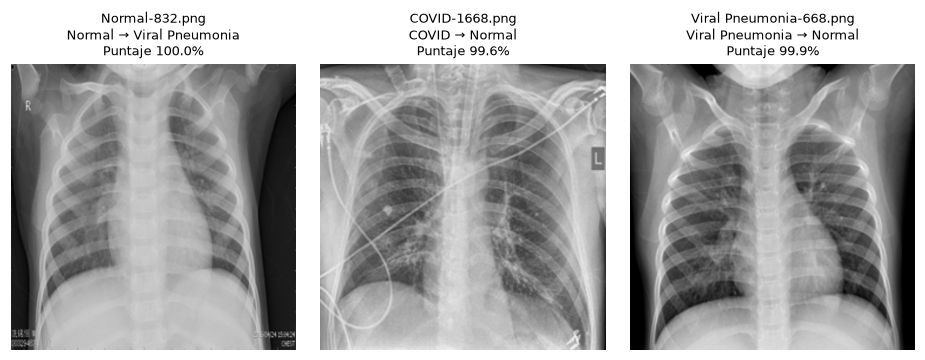

In [11]:
if hay_imagenes:
    # Mostrar un error de alta confianza por clase real como ejemplo.
    errores = predicciones.loc[real != predicho].copy()
    errores["puntaje"] = probabilidades.max(axis=1)[real != predicho]
    figura, ejes = plt.subplots(1, 3, figsize=(9, 3.3))
    for eje, etiqueta in zip(ejes, clases):
        eje.axis("off")
        ejemplo = errores[errores.label == etiqueta].nlargest(1, "puntaje")
        if ejemplo.empty:
            eje.set_title(f"{etiqueta} · sin errores")
            continue
        fila = ejemplo.iloc[0]
        with Image.open(raiz / fila.path) as imagen:
            eje.imshow(imagen.convert("L"), cmap="gray", vmin=0, vmax=255)
        eje.set_title(f"{Path(fila.path).name}\n{fila.label} → {fila.predicted_label}\nPuntaje {fila.puntaje:.1%}", fontsize=9)
    figura.tight_layout()
    mostrar_figura(figura)
else:
    print("Descargá las imágenes según el README para ejecutar esta celda.")

## 6. Qué aprendimos

La red superó a la referencia mayoritaria en las tres métricas. La confusión más común fue entre Normal y COVID-19. El resultado describe las etiquetas de esta colección. Las fuentes están asociadas con las clases, y la falta de identificadores impide comprobar que los pacientes sean distintos entre particiones.

[Manifiesto](data/processed/manifest.csv) · [Partición fija](data/processed/splits.csv) · [Predicciones de test](results/baseline/test_predictions.csv)